In [140]:
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
import numpy as np
from scipy.optimize import minimize
from collections import defaultdict


from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit.primitives import StatevectorSampler
from qiskit.primitives import StatevectorEstimator

from qiskit_addon_opt_mapper.applications import Maxcut
from qiskit_addon_opt_mapper.converters import OptimizationProblemToQubo
from qiskit_addon_opt_mapper.translators import to_ising


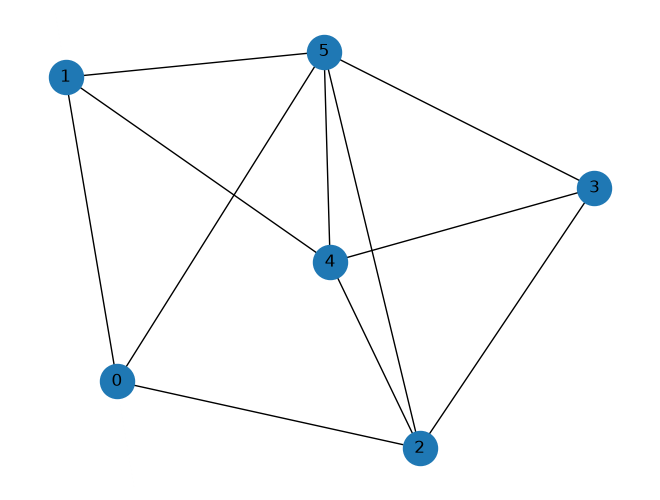

In [141]:
n_small = 6

graph = rx.PyGraph()
graph.add_nodes_from(np.arange(0, n_small, 1))
edge_list = [
    (0, 1, 1.0),
    (0, 5, 1.0),
    (0, 2, 1.0),
    (1, 5, 1.0),
    (1, 4, 1.0),
    (2, 5, 1.0),
    (3, 2, 1.0),
    (3, 5, 1.0),
    (4, 5, 1.0),
    (4, 2, 1.0),
    (4, 3, 1.0),
]
graph.add_edges_from(edge_list)
draw_graph(graph, node_size=600, with_labels=True)


In [142]:
# Max-cut model

maxcut = Maxcut(graph)
maxcut_problem = maxcut.to_optimization_problem()
print(maxcut_problem.prettyprint())


Problem name: Max-cut

Maximize
  -2*x_0*x_1 - 2*x_0*x_2 - 2*x_0*x_5 - 2*x_1*x_4 - 2*x_1*x_5 - 2*x_2*x_3
  - 2*x_2*x_4 - 2*x_2*x_5 - 2*x_3*x_4 - 2*x_3*x_5 - 2*x_4*x_5 + 3*x_0 + 3*x_1
  + 4*x_2 + 3*x_3 + 4*x_4 + 5*x_5

Subject to
  No constraints

  Binary variables (6)
    x_0 x_1 x_2 x_3 x_4 x_5



In [143]:
# Build cost hamiltonian

qubo = OptimizationProblemToQubo().convert(maxcut_problem)
cost_hamiltonian, offset = to_ising(qubo)

print("Cost Hamiltonian:", cost_hamiltonian)
print("Offset", offset)


Cost Hamiltonian: SparsePauliOp(['IIIIZZ', 'IIIZIZ', 'ZIIIIZ', 'IZIIZI', 'ZIIIZI', 'IIZZII', 'IZIZII', 'ZIIZII', 'IZZIII', 'ZIZIII', 'ZZIIII'],
              coeffs=[0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j,
 0.5+0.j, 0.5+0.j, 0.5+0.j])
Offset -5.5


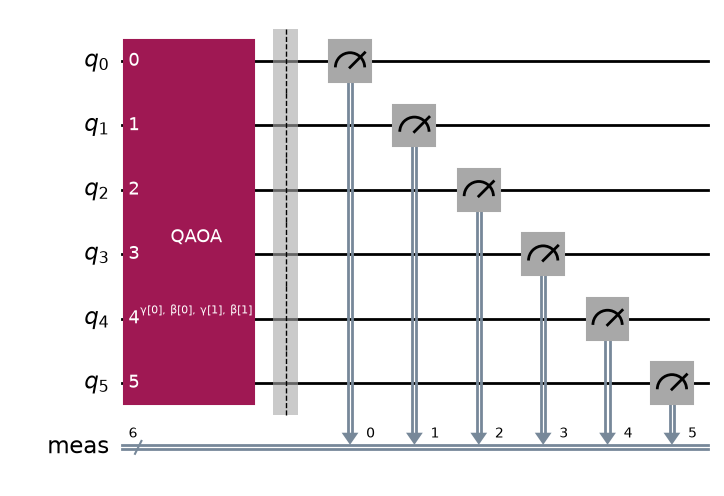

In [144]:
# Build QAOA ansatz
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=2)
circuit.measure_all()

circuit.draw("mpl")


In [145]:
circuit.parameters


ParameterView([ParameterVectorElement(β[0]), ParameterVectorElement(β[1]), ParameterVectorElement(γ[0]), ParameterVectorElement(γ[1])])

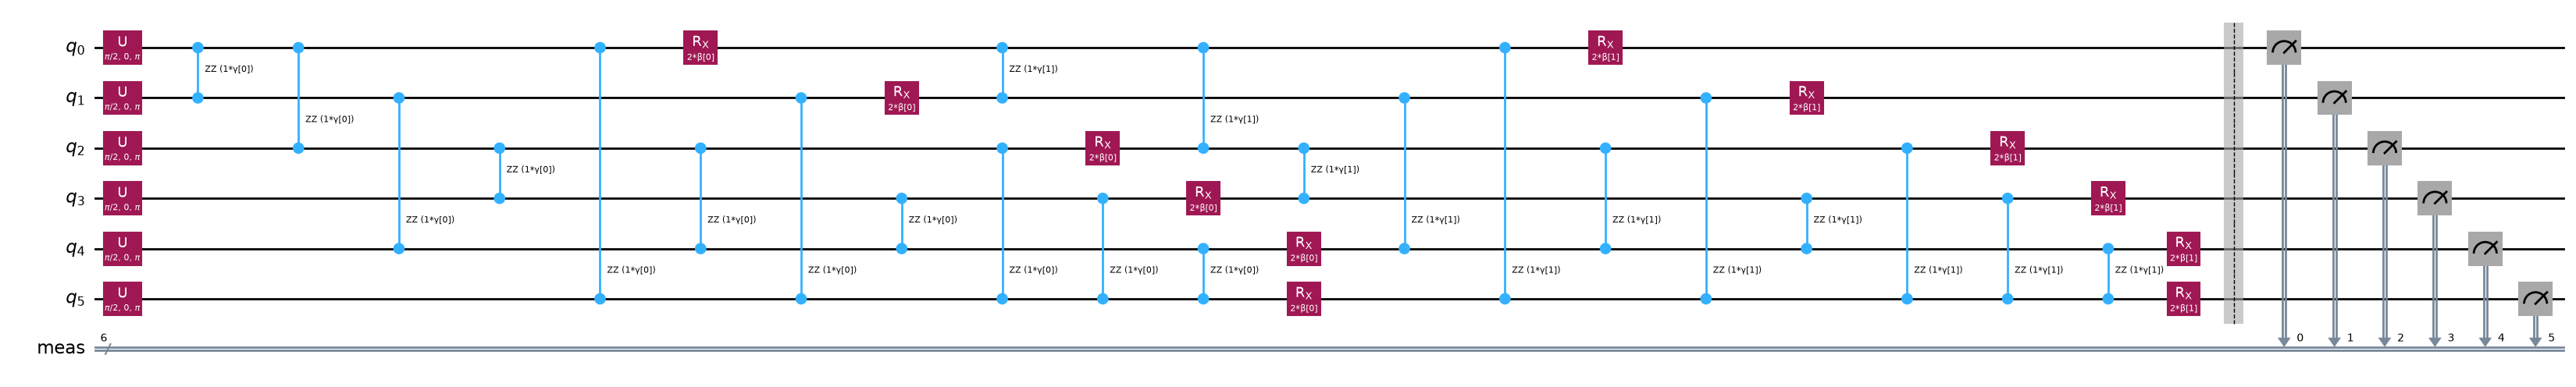

In [147]:
# Visualize circuit
circuit.decompose(reps=2).draw("mpl", fold=False)


In [148]:
# Any bounded angles will work

initial_gamma = np.pi
initial_beta = np.pi / 2
init_params = [initial_beta, initial_beta, initial_gamma, initial_gamma]


In [149]:
def cost_func_estimator(params, ansatz, hamiltonian, estimator):
    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost


In [150]:
objective_func_vals = []  # Global variable

estimator = StatevectorEstimator()

estimator_circuit = circuit.remove_final_measurements(inplace=False)

result = minimize(
    cost_func_estimator,
    init_params,
    args=(estimator_circuit, cost_hamiltonian, estimator),
    method="COBYLA",
    tol=1e-2,
)
print(result)


 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -1.2458567902477875
       x: [ 3.096e+00  1.858e+00  2.652e+00  3.145e+00]
    nfev: 40
   maxcv: 0.0


In [151]:
sampler = StatevectorSampler()

pub = (optimized_circuit,)
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val / shots for key, val in counts_int.items()}
final_distribution_bin = {key: val / shots for key, val in counts_bin.items()}
print(final_distribution_int)


{49: 0.0575, 36: 0.0294, 27: 0.0305, 7: 0.0151, 10: 0.0052, 14: 0.0572, 48: 0.0303, 28: 0.0127, 41: 0.042, 52: 0.0361, 46: 0.0182, 22: 0.0386, 42: 0.0427, 11: 0.0359, 21: 0.0428, 45: 0.0055, 37: 0.0205, 29: 0.0096, 17: 0.0162, 53: 0.0047, 50: 0.0238, 26: 0.0217, 15: 0.028, 56: 0.0167, 13: 0.0226, 44: 0.0165, 57: 0.0184, 30: 0.0107, 6: 0.0173, 25: 0.0544, 54: 0.0059, 19: 0.0144, 38: 0.0578, 20: 0.013, 40: 0.0128, 8: 0.0025, 18: 0.0048, 39: 0.002, 12: 0.0022, 33: 0.0091, 61: 0.0031, 35: 0.0112, 1: 0.0029, 31: 0.0028, 23: 0.0094, 2: 0.0027, 5: 0.0049, 43: 0.016, 32: 0.0026, 55: 0.0023, 34: 0.0111, 62: 0.0034, 58: 0.0047, 9: 0.0051, 16: 0.0009, 51: 0.0019, 0: 0.0014, 63: 0.0014, 60: 0.0003, 59: 0.0013, 4: 0.0017, 47: 0.0011, 24: 0.0022, 3: 0.0003}


In [152]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]


keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(graph))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)

partition = maxcut.interpret(np.array(most_likely_bitstring))
print("Partition:", partition)


Result bitstring: [0, 1, 1, 0, 0, 1]
Partition: [[0, 3, 4], [1, 2, 5]]


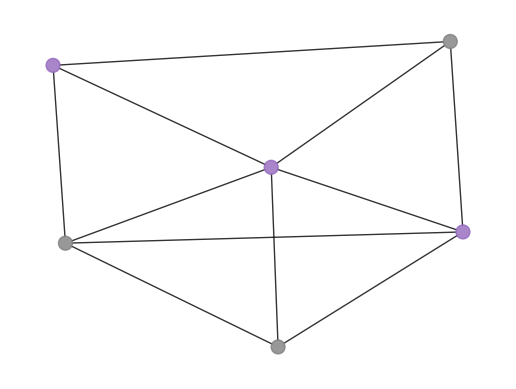

In [153]:
# auxiliary function to plot graphs
def plot_result(G, x):
    colors = ["tab:grey" if i == 0 else "tab:purple" for i in x]
    pos, _default_axes = rx.spring_layout(G), plt.axes(frameon=True)
    rx.visualization.mpl_draw(
        G, node_color=colors, node_size=100, alpha=0.8, pos=pos
    )


plot_result(graph, most_likely_bitstring)


In [154]:
cut_value = maxcut_problem.objective.evaluate(np.array(most_likely_bitstring))
print("The value of the cut is:", cut_value)
print("Cut value implied by the optimized cost:", -(result.fun + offset))


The value of the cut is: 8.0
Cut value implied by the optimized cost: 6.745856790247787


In [155]:
# Classical baseline: enumerate all 2**n_small bitstrings and take the best cut.
def brute_force_max_cut(problem) -> tuple[int, list[int]]:
    n = problem.get_num_vars()
    best_cut = -1
    best_x: list[int] = []
    for i in range(2**n):
        x = np.array([(i >> k) & 1 for k in range(n)])
        cut = problem.objective.evaluate(x)
        if cut > best_cut:
            best_cut = int(cut)
            best_x = x.tolist()
    return best_cut, best_x


classical_best, classical_x = brute_force_max_cut(maxcut_problem)
print(f"Classical optimum (brute force): {classical_best}")
print(f"QAOA cut value:                  {cut_value}")


Classical optimum (brute force): 8
QAOA cut value:                  8.0
